# Validacion completa en QPU — Dynamical Decoupling

## Objetivo
Validar en **un solo job** que el control por software (CPMG / XY4) extiende
el tiempo util de coherencia frente a evolucion libre.

## Diseno eficiente (ahorro de tiempo de cola)
1. **Seleccion explicita del mejor qubit** (T2 alto, error 1Q bajo).
2. **Un unico lote**: (libre, CPMG, XY4) x tiempos.
3. **Analisis offline**: ajuste estirado A*exp(-(t/T2)^beta)+C y graficas.

## Hipotesis
| Hipotesis | Evidencia esperada |
|-----------|-------------------|
| DD preserva coherencia | |X|_CPMG/XY4 > |X|_libre a t iguales |
| Extension de T2 | T2_CPMG > T2* del fit |
| Ruido baja frecuencia | beta > 1 en el fit estirado |

## Requisitos Kaggle
1. Internet ON
2. Secret `IBM_QUANTUM_TOKEN`
3. Restart si el kernel lo pide tras pip


## 1. Instalacion


In [13]:
%pip install -q "qiskit>=1.0" "qiskit-ibm-runtime>=0.23" matplotlib scipy
print("OK")


Note: you may need to restart the kernel to use updated packages.
OK


## 2. Circuitos y utilidades


In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from qiskit import QuantumCircuit, transpile

def build_free(t_us: float) -> QuantumCircuit:
    qc = QuantumCircuit(1, 1, name=f"free_{t_us}")
    qc.h(0)
    if t_us > 0:
        qc.delay(float(t_us), 0, unit="us")
    qc.h(0)
    qc.measure(0, 0)
    return qc


def build_cpmg(t_us: float, n_pulses: int = 6) -> QuantumCircuit:
    qc = QuantumCircuit(1, 1, name=f"cpmg_{t_us}_N{n_pulses}")
    qc.h(0)
    if n_pulses >= 1 and t_us > 0:
        seg = t_us / n_pulses
        for _ in range(n_pulses):
            h = seg / 2.0
            if h > 0:
                qc.delay(h, 0, unit="us")
            qc.x(0)
            if h > 0:
                qc.delay(h, 0, unit="us")
    elif t_us > 0:
        qc.delay(float(t_us), 0, unit="us")
    qc.h(0)
    qc.measure(0, 0)
    return qc


def build_xy4(t_us: float, n_cycles: int = 2) -> QuantumCircuit:
    """XY4: (X-tau-Y-tau-X-tau-Y-tau) * n_cycles."""
    axes = (["x", "y", "x", "y"] * max(n_cycles, 1))
    n = len(axes)
    qc = QuantumCircuit(1, 1, name=f"xy4_{t_us}_C{n_cycles}")
    qc.h(0)
    if n >= 1 and t_us > 0:
        seg = t_us / n
        for a in axes:
            h = seg / 2.0
            if h > 0:
                qc.delay(h, 0, unit="us")
            if a == "x":
                qc.x(0)
            else:
                qc.y(0)
            if h > 0:
                qc.delay(h, 0, unit="us")
    elif t_us > 0:
        qc.delay(float(t_us), 0, unit="us")
    qc.h(0)
    qc.measure(0, 0)
    return qc


def expect_x(counts: dict) -> float:
    n0 = n1 = 0
    for k, v in counts.items():
        bit = str(k).replace(" ", "")[-1]
        if bit == "0":
            n0 += int(v)
        else:
            n1 += int(v)
    tot = n0 + n1
    return (n0 - n1) / tot if tot else 0.0


def counts_from_pub(pub) -> dict:
    data = pub.data
    if hasattr(data, "c"):
        return data.c.get_counts()
    for key in data:
        try:
            return data[key].get_counts()
        except Exception:
            continue
    return {}


def get_token() -> str:
    try:
        from kaggle_secrets import UserSecretsClient
        t = UserSecretsClient().get_secret("IBM_QUANTUM_TOKEN")
        if t:
            return t.strip()
    except Exception:
        pass
    t = os.environ.get("QISKIT_IBM_TOKEN") or os.environ.get("IBM_QUANTUM_TOKEN")
    if not t:
        raise RuntimeError("Configure secret IBM_QUANTUM_TOKEN")
    return t.strip()


def stretched_exp(t, A, T2, beta, C):
    return A * np.exp(-((np.maximum(t, 1e-12) / max(T2, 1e-12)) ** beta)) + C


def fit_t2(times, signal):
    y = np.abs(np.asarray(signal, dtype=float))
    t = np.asarray(times, dtype=float)
    if len(t) < 3 or np.nanmax(y) < 0.05:
        return None
    A0 = float(np.clip(y[0] - y[-1], 0.05, 1.0))
    C0 = float(np.clip(y[-1], -0.2, 0.5))
    T0 = float(np.clip(t[len(t) // 2], 1.0, t[-1]))
    try:
        popt, pcov = curve_fit(
            stretched_exp, t, y,
            p0=[A0, T0, 1.2, C0],
            bounds=([0.0, 0.1, 0.3, -0.3], [1.5, t[-1] * 5, 3.0, 0.6]),
            maxfev=8000,
        )
        A, T2, beta, C = popt
        perr = np.sqrt(np.diag(pcov))
        return {
            "A": float(A), "T2": float(T2), "beta": float(beta), "C": float(C),
            "T2_err": float(perr[1]), "beta_err": float(perr[2]),
            "y_fit": stretched_exp(t, *popt),
        }
    except Exception as e:
        print("Fit fallo:", e)
        return None


print("Utilidades listas.")


Utilidades listas.


## 3. Un solo job: mejor qubit + lote (libre, CPMG, XY4) x tiempos


In [15]:
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

T_STEPS = [2.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0]
N_CPMG = 6
N_XY4_CYCLES = 2
SHOTS = 2048
BACKEND_NAME = "ibm_fez"
PROTOCOLS = ("free", "cpmg", "xy4")

token = get_token()
QiskitRuntimeService.save_account(
    channel="ibm_cloud", token=token, instance="open-instance",
    overwrite=True, set_as_default=True,
)
service = QiskitRuntimeService(channel="ibm_cloud", instance="open-instance")

ops = service.backends(operational=True, simulator=False)
names = [b.name for b in ops]
print("Backends:", names)
backend = service.backend(BACKEND_NAME) if BACKEND_NAME in names else ops[0]
print("Usando:", backend.name)


def pick_best_qubit(backend):
    props = backend.properties()
    best_q, best_score = 0, -1.0
    rows = []
    for q in range(backend.num_qubits):
        try:
            t2 = props.t2(q)
        except Exception:
            continue
        if t2 is None:
            continue
        err = None
        for g in ("sx", "x"):
            try:
                err = props.gate_error(g, [q])
                break
            except Exception:
                pass
        t2_us = t2 * 1e6
        gate_pen = err if err is not None else 0.01
        score = t2_us / (1.0 + 50.0 * gate_pen)
        rows.append((q, t2_us, err, score))
        if score > best_score:
            best_score, best_q = score, q
    rows.sort(key=lambda r: -r[3])
    print("Top 5 qubits (T2 / error):")
    for q, t2u, err, sc in rows[:5]:
        print(f"  q={q:3d}  T2={t2u:7.1f} us  err={err}  score={sc:.2f}")
    if not rows:
        print("Sin T2 en propiedades; usando qubit 0")
        return 0
    print("Seleccionado qubit fisico:", best_q)
    return best_q


qubit = pick_best_qubit(backend)

circuits = []
index = []
for t in T_STEPS:
    circuits.append(build_free(t)); index.append(("free", t))
    circuits.append(build_cpmg(t, N_CPMG)); index.append(("cpmg", t))
    circuits.append(build_xy4(t, N_XY4_CYCLES)); index.append(("xy4", t))

print(f"Circuitos en el lote: {len(circuits)}  (1 job, {SHOTS} shots)")

transpiled = transpile(
    circuits, backend=backend, optimization_level=1, initial_layout=[qubit],
)

sampler = SamplerV2(mode=backend)
job = sampler.run(transpiled, shots=SHOTS)
print("Job ID:", job.job_id())
print("Esperando (unica espera de cola)...")
result = job.result()
print("Job completado.")

JOB_ID = job.job_id()
BACKEND_USED = backend.name
QUBIT_USED = qubit
INDEX = index
RESULT = result
T_STEPS_ARR = np.array(T_STEPS, dtype=float)


Backends: ['ibm_fez', 'ibm_kingston', 'ibm_marrakesh']
Usando: ibm_fez
Top 5 qubits (T2 / error):
  q=142  T2=  265.1 us  err=0.0003976411056252661  score=259.89
  q= 15  T2=  257.4 us  err=0.0002456479545288483  score=254.31
  q= 88  T2=  252.8 us  err=0.0003841744382059813  score=248.03
  q=127  T2=  213.0 us  err=0.00027888631720206653  score=210.04
  q=  1  T2=  211.6 us  err=0.000340812727879291  score=208.04
Seleccionado qubit fisico: 142
Circuitos en el lote: 21  (1 job, 2048 shots)


/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 42 [dt] = 1.680000e-07 [s] from 1.666667e-07 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 31 [dt] = 1.240000e-07 [s] from 1.250000e-07 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 104 [dt] = 4.160000e-07 [s] from 4.166667e-07 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 78 [dt] = 3.120000e-07 [s] from 3.125000e-07 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 208 [dt] = 8.320000e-07 [s] from 8.333333e-07 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 156 [dt] = 6.240000e-07 [s

Job ID: daphuqr18flc739mb47g
Esperando (unica espera de cola)...
Job completado.


## 4. Analisis offline: tabla, fits T2 y graficas


Backend=ibm_fez  qubit=142  job=daphuqr18flc739mb47g

  t (us)       free       cpmg        xy4   cpmg/free    xy4/free
----------------------------------------------------------------
     2.0    +0.9229    +0.9746    +0.9766        1.06x        1.06x
     5.0    +0.6680    +0.9561    +0.9561        1.43x        1.43x
    10.0    -0.1113    +0.9385    +0.9287        8.43x        8.34x
    15.0    -0.7236    +0.9092    +0.8975        1.26x        1.24x
    20.0    -0.8047    +0.8867    +0.8516        1.10x        1.06x
    25.0    -0.4082    +0.8545    +0.8223        2.09x        2.01x
    30.0    +0.2422    +0.8398    +0.8271        3.47x        3.42x

Fit free: T2=5.20+/-8.76 us  beta=3.00+/-208.50  A=0.494  C=0.459

Fit cpmg: T2=55.88+/-123.44 us  beta=1.21+/-0.52  A=0.380  C=0.600

Fit xy4: T2=48.43+/-242.80 us  beta=1.02+/-1.20  A=0.394  C=0.600


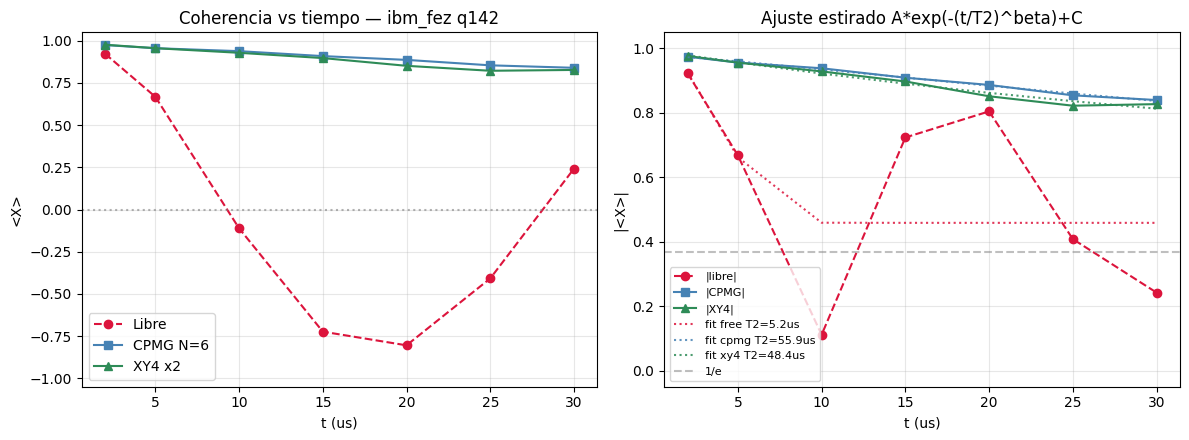


|<X>| medio  libre=0.554  CPMG=0.908  XY4=0.894
T2_CPMG / T2* ~ 10.74x
beta_CPMG=1.21 > 1 -> ruido de baja frecuencia (DD pertinente).
RESULTADO: se valida la hipotesis — DD aporta estabilidad efectiva en el QPU.


In [16]:
series = {p: [] for p in PROTOCOLS}
for i, (prot, t) in enumerate(INDEX):
    series[prot].append(expect_x(counts_from_pub(RESULT[i])))
for p in PROTOCOLS:
    series[p] = np.array(series[p], dtype=float)

print(f"Backend={BACKEND_USED}  qubit={QUBIT_USED}  job={JOB_ID}\n")
print(f"{'t (us)':>8}  {'free':>9}  {'cpmg':>9}  {'xy4':>9}  {'cpmg/free':>10}  {'xy4/free':>10}")
print("-" * 64)
for i, t in enumerate(T_STEPS_ARR):
    xf, xc, xy = series["free"][i], series["cpmg"][i], series["xy4"][i]
    print(f"{t:8.1f}  {xf:+9.4f}  {xc:+9.4f}  {xy:+9.4f}  "
          f"{abs(xc)/max(abs(xf),1e-9):10.2f}x  {abs(xy)/max(abs(xf),1e-9):10.2f}x")

fits = {}
for p in PROTOCOLS:
    fits[p] = fit_t2(T_STEPS_ARR, series[p])
    if fits[p]:
        f = fits[p]
        print(f"\nFit {p}: T2={f['T2']:.2f}+/-{f['T2_err']:.2f} us  "
              f"beta={f['beta']:.2f}+/-{f['beta_err']:.2f}  A={f['A']:.3f}  C={f['C']:.3f}")
    else:
        print(f"\nFit {p}: no convergente")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.plot(T_STEPS_ARR, series["free"], "o--", color="crimson", label="Libre")
ax.plot(T_STEPS_ARR, series["cpmg"], "s-", color="steelblue", label=f"CPMG N={N_CPMG}")
ax.plot(T_STEPS_ARR, series["xy4"], "^-", color="seagreen", label=f"XY4 x{N_XY4_CYCLES}")
ax.axhline(0, color="gray", ls=":", alpha=0.6)
ax.set_xlabel("t (us)"); ax.set_ylabel("<X>")
ax.set_title(f"Coherencia vs tiempo — {BACKEND_USED} q{QUBIT_USED}")
ax.legend(); ax.grid(True, alpha=0.3); ax.set_ylim(-1.05, 1.05)

ax = axes[1]
ax.plot(T_STEPS_ARR, np.abs(series["free"]), "o--", color="crimson", label="|libre|")
ax.plot(T_STEPS_ARR, np.abs(series["cpmg"]), "s-", color="steelblue", label="|CPMG|")
ax.plot(T_STEPS_ARR, np.abs(series["xy4"]), "^-", color="seagreen", label="|XY4|")
for p, col in (("free", "crimson"), ("cpmg", "steelblue"), ("xy4", "seagreen")):
    if fits[p] is not None:
        ax.plot(T_STEPS_ARR, fits[p]["y_fit"], ":", color=col, alpha=0.85,
                label=f"fit {p} T2={fits[p]['T2']:.1f}us")
ax.axhline(1 / np.e, color="gray", ls="--", alpha=0.5, label="1/e")
ax.set_xlabel("t (us)"); ax.set_ylabel("|<X>|")
ax.set_title("Ajuste estirado A*exp(-(t/T2)^beta)+C")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3); ax.set_ylim(-0.05, 1.05)
plt.tight_layout(); plt.show()

print("\n" + "=" * 64)
mf = float(np.mean(np.abs(series["free"])))
mc = float(np.mean(np.abs(series["cpmg"])))
mx = float(np.mean(np.abs(series["xy4"])))
print(f"|<X>| medio  libre={mf:.3f}  CPMG={mc:.3f}  XY4={mx:.3f}")
if fits["free"] and fits["cpmg"] and fits["free"]["T2"] > 0:
    print(f"T2_CPMG / T2* ~ {fits['cpmg']['T2']/fits['free']['T2']:.2f}x")
    if fits["cpmg"]["beta"] > 1.15:
        print(f"beta_CPMG={fits['cpmg']['beta']:.2f} > 1 -> ruido de baja frecuencia (DD pertinente).")
if (mc > mf * 1.25) or (mx > mf * 1.25):
    print("RESULTADO: se valida la hipotesis — DD aporta estabilidad efectiva en el QPU.")
else:
    print("RESULTADO: ventaja no concluyente; revisar qubit/N/tiempos.")
print("=" * 64)


## 5. Interpretacion

### Demostrado si el veredicto es positivo
- CPMG y/o XY4 mantienen |<X>| por encima de la evolucion libre a igualdad de t.
- El fit aporta T2 comparable y beta diagnostica el tipo de ruido.

### No implementado aun (mas jobs)
| Avance | Estado |
|--------|--------|
| ACLDD adaptativo online | No (requiere lazos / varios jobs) |
| Barrido 2D (N, tau) | No |
| Crosstalk multiqubit | No |

### Eficiencia
**1 job**, 3 x |T| circuitos. Seleccion de qubit y analisis sin colas extra.


<>:94: SyntaxWarning: invalid escape sequence '\~'
<>:94: SyntaxWarning: invalid escape sequence '\~'
/tmp/ipykernel_115/1883983092.py:94: SyntaxWarning: invalid escape sequence '\~'
  print(f"T2_CPMG / T2* \~ {fits_l['cpmg']['T2']/fits_l['free']['T2']:.2f}x")


Reutilizando qubit de la sesion: 142
Lote largo: 30 circuitos -> 1 job


/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 104 [dt] = 4.160000e-07 [s] from 4.166667e-07 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 78 [dt] = 3.120000e-07 [s] from 3.125000e-07 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 208 [dt] = 8.320000e-07 [s] from 8.333333e-07 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 156 [dt] = 6.240000e-07 [s] from 6.250000e-07 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 417 [dt] = 1.668000e-06 [s] from 1.666667e-06 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 312 [dt] = 1.248000e-06 

Job ID (T largo): dapi3q2c505c73ci8v6g
Job largo completado.

  t (us)       free       cpmg        xy4
------------------------------------------
     5.0    +0.6475    +0.9531    +0.9482
    10.0    -0.0967    +0.9238    +0.9316
    20.0    -0.8262    +0.8760    +0.8789
    40.0    +0.6582    +0.8076    +0.8057
    60.0    -0.4756    +0.7041    +0.7109
    80.0    +0.2744    +0.6318    +0.6250
   100.0    -0.1348    +0.5723    +0.5752
   120.0    -0.0381    +0.4893    +0.5137
   150.0    +0.3145    +0.4238    +0.4834
   200.0    -0.1875    +0.2646    +0.3555
Fit free: T2=76.94+/-38.64 us  beta=3.00
Fit cpmg: T2=249.45+/-130.36 us  beta=1.05
Fit xy4: T2=144.46+/-48.88 us  beta=1.05


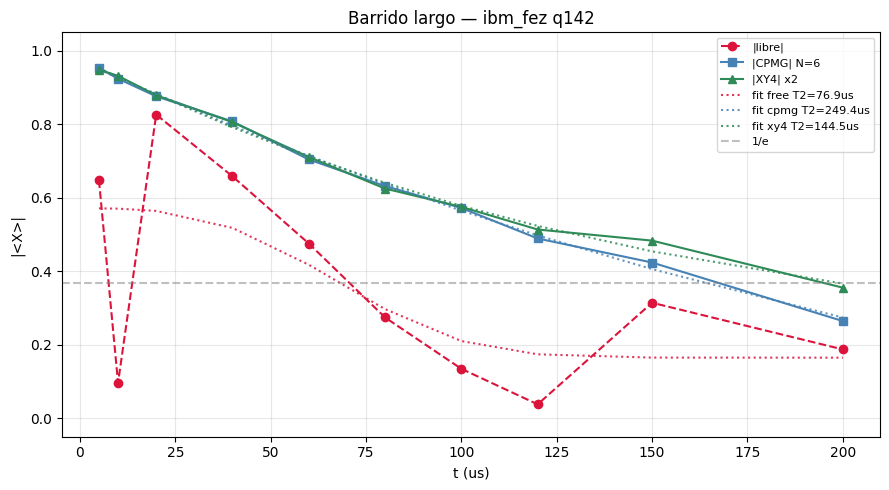

T2_CPMG / T2* \~ 3.24x


In [17]:
# ===== EXTENSION: barrido temporal largo (T hasta 200 us) — 1 job =====
from qiskit import transpile
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

T_STEPS_LONG = [5.0, 10.0, 20.0, 40.0, 60.0, 80.0, 100.0, 120.0, 150.0, 200.0]
N_CPMG_L = 6
N_XY4_L = 2
SHOTS_L = 2048
BACKEND_L = "ibm_fez"

token = get_token()
QiskitRuntimeService.save_account(
    channel="ibm_cloud", token=token, instance="open-instance",
    overwrite=True, set_as_default=True,
)
service = QiskitRuntimeService(channel="ibm_cloud", instance="open-instance")
ops = service.backends(operational=True, simulator=False)
names = [b.name for b in ops]
backend = service.backend(BACKEND_L) if BACKEND_L in names else ops[0]

# Reutilizar el mismo criterio de qubit (o el QUBIT_USED de la sesion si existe)
try:
    q_use = QUBIT_USED
    print(f"Reutilizando qubit de la sesion: {q_use}")
except NameError:
    props = backend.properties()
    best_q, best_score = 0, -1.0
    for q in range(backend.num_qubits):
        try:
            t2 = props.t2(q)
        except Exception:
            continue
        if t2 is None:
            continue
        err = 0.01
        for g in ("sx", "x"):
            try:
                err = props.gate_error(g, [q]); break
            except Exception:
                pass
        score = (t2 * 1e6) / (1.0 + 50.0 * err)
        if score > best_score:
            best_score, best_q = score, q
    q_use = best_q
    print(f"Qubit seleccionado: {q_use}")

circuits_l, index_l = [], []
for t in T_STEPS_LONG:
    circuits_l.append(build_free(t));              index_l.append(("free", t))
    circuits_l.append(build_cpmg(t, N_CPMG_L));    index_l.append(("cpmg", t))
    circuits_l.append(build_xy4(t, N_XY4_L));      index_l.append(("xy4", t))

print(f"Lote largo: {len(circuits_l)} circuitos -> 1 job")
trans_l = transpile(circuits_l, backend=backend, optimization_level=1, initial_layout=[q_use])
job_l = SamplerV2(mode=backend).run(trans_l, shots=SHOTS_L)
print(f"Job ID (T largo): {job_l.job_id()}")
res_l = job_l.result()
print("Job largo completado.")

series_l = {"free": [], "cpmg": [], "xy4": []}
for i, (prot, t) in enumerate(index_l):
    series_l[prot].append(expect_x(counts_from_pub(res_l[i])))
for p in series_l:
    series_l[p] = np.array(series_l[p], dtype=float)
t_long = np.array(T_STEPS_LONG, dtype=float)

print(f"\n{'t (us)':>8}  {'free':>9}  {'cpmg':>9}  {'xy4':>9}")
print("-" * 42)
for i, t in enumerate(t_long):
    print(f"{t:8.1f}  {series_l['free'][i]:+9.4f}  {series_l['cpmg'][i]:+9.4f}  {series_l['xy4'][i]:+9.4f}")

fits_l = {p: fit_t2(t_long, series_l[p]) for p in ("free", "cpmg", "xy4")}
for p, f in fits_l.items():
    if f:
        print(f"Fit {p}: T2={f['T2']:.2f}+/-{f['T2_err']:.2f} us  beta={f['beta']:.2f}")
    else:
        print(f"Fit {p}: no convergente")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(t_long, np.abs(series_l["free"]), "o--", color="crimson", label="|libre|")
ax.plot(t_long, np.abs(series_l["cpmg"]), "s-", color="steelblue", label=f"|CPMG| N={N_CPMG_L}")
ax.plot(t_long, np.abs(series_l["xy4"]), "^-", color="seagreen", label=f"|XY4| x{N_XY4_L}")
for p, col in (("free", "crimson"), ("cpmg", "steelblue"), ("xy4", "seagreen")):
    if fits_l[p] is not None:
        ax.plot(t_long, fits_l[p]["y_fit"], ":", color=col, alpha=0.85,
                label=f"fit {p} T2={fits_l[p]['T2']:.1f}us")
ax.axhline(1/np.e, color="gray", ls="--", alpha=0.5, label="1/e")
ax.set_xlabel("t (us)"); ax.set_ylabel("|<X>|")
ax.set_title(f"Barrido largo — {backend.name} q{q_use}")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3); ax.set_ylim(-0.05, 1.05)
plt.tight_layout(); plt.show()

if fits_l["free"] and fits_l["cpmg"] and fits_l["free"]["T2"] > 0:
    print(f"T2_CPMG / T2* \~ {fits_l['cpmg']['T2']/fits_l['free']['T2']:.2f}x")

Escalado N @ t=60.0 us: 7 circuitos


/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 938 [dt] = 3.752000e-06 [s] from 3.750000e-06 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 469 [dt] = 1.876000e-06 [s] from 1.875000e-06 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 312 [dt] = 1.248000e-06 [s] from 1.250000e-06 [s]
  warnings.warn(


Job ID (N-sweep): dapi4a318flc739mbatg
Job N-sweep completado.

   N        <X>      |<X>|
----------------------------
   2    +0.6992     0.6992
   4    +0.6914     0.6914
   6    +0.6914     0.6914
   8    +0.7061     0.7061
  12    +0.7148     0.7148
  16    +0.7188     0.7188
  24    +0.6973     0.6973


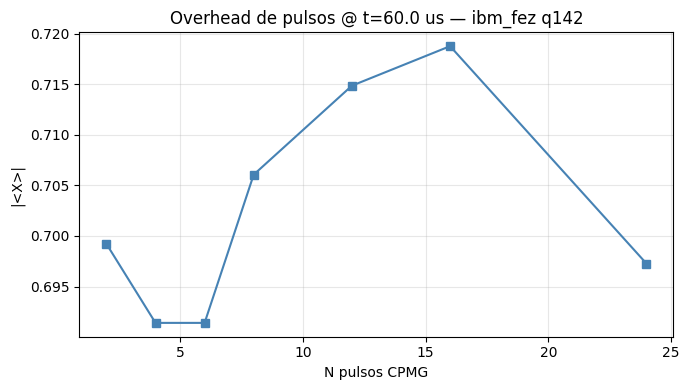

N optimo (max |<X>|): 16


In [18]:
# ===== EXTENSION: escalado de N a t fijo — 1 job =====
T_FIXED = 60.0  # us (punto intermedio del barrido largo)
N_LIST = [2, 4, 6, 8, 12, 16, 24]
SHOTS_N = 2048

circuits_n, n_vals = [], []
for n in N_LIST:
    circuits_n.append(build_cpmg(T_FIXED, n_pulses=n))
    n_vals.append(n)

print(f"Escalado N @ t={T_FIXED} us: {len(circuits_n)} circuitos")
trans_n = transpile(circuits_n, backend=backend, optimization_level=1, initial_layout=[q_use])
job_n = SamplerV2(mode=backend).run(trans_n, shots=SHOTS_N)
print(f"Job ID (N-sweep): {job_n.job_id()}")
res_n = job_n.result()
print("Job N-sweep completado.")

x_vs_n = [expect_x(counts_from_pub(res_n[i])) for i in range(len(N_LIST))]
print(f"\n{'N':>4}  {'<X>':>9}  {'|<X>|':>9}")
print("-" * 28)
for n, x in zip(N_LIST, x_vs_n):
    print(f"{n:4d}  {x:+9.4f}  {abs(x):9.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(N_LIST, np.abs(x_vs_n), "s-", color="steelblue")
ax.set_xlabel("N pulsos CPMG"); ax.set_ylabel("|<X>|")
ax.set_title(f"Overhead de pulsos @ t={T_FIXED} us — {backend.name} q{q_use}")
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

n_opt = N_LIST[int(np.argmax(np.abs(x_vs_n)))]
print(f"N optimo (max |<X>|): {n_opt}")